# Artificial Intelligence

* Md. Jalil Piran
* Sejong University
* piran@sejong.ac.kr


## K-means Clustering: Model Selection, Evaluation, and Prediction

### Discovering groups in a two-dimensional dataset

- **Goal:** Apply K-means to group observations using `Feature_1` and `Feature_2`.
- **Learning type:** Unsupervised learning. The true labels are **not** used to fit K-means or select the number of clusters.
- **Main topics:** feature scaling, the elbow method, silhouette analysis, centroid interpretation, label matching, and prediction for new observations.
- **Environment:** This notebook supports Google Colab and a local Jupyter/Anaconda environment.

**Before you begin:** Place `Clustering_dataset_2.csv` in the same folder as this notebook, or update `DATA_PATH` in the configuration cell. In Google Colab, you may instead mount Google Drive.

| Concept | This experiment |
|---|---|
| Learning type | Unsupervised clustering |
| Input features | `Feature_1`, `Feature_2` |
| Reference labels | `True_Cluster`, used only for post-clustering evaluation |
| Algorithm | K-means |
| Model output | Predicted cluster ID and centroid |
| Model selection | Elbow method and silhouette score |
| Evaluation | Silhouette analysis and optional label agreement |
| Prediction | Assign new observations to their nearest learned centroid |

**Important distinction:** K-means does not know the meaning of `True_Cluster`. Its cluster IDs are arbitrary. A predicted cluster numbered `0` is not automatically equivalent to true class `0`.

### 1. Import libraries

Import the numerical, data-management, visualization, clustering, evaluation, and label-matching tools. Warnings are suppressed here to keep the teaching output concise; in research code, inspect warnings before suppressing them.

In [2]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    confusion_matrix,
    adjusted_rand_score,
    normalized_mutual_info_score
)

from scipy.optimize import linear_sum_assignment

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


### 2. Configure the dataset location

Choose the option that matches your environment.

- **Google Colab:** set `USE_GOOGLE_DRIVE = True`. The notebook mounts Drive and looks in the specified folder.
- **Local Jupyter / Anaconda:** set `USE_GOOGLE_DRIVE = False`. Put the CSV beside the notebook or specify its full path in `DATA_PATH`.
- Do not import `google.colab` in a local Anaconda environment.

In [3]:
USE_GOOGLE_DRIVE = False  # Change to True when running in Google Colab

# Local Jupyter / Anaconda path:
DATA_PATH = Path("Clustering_dataset_2.csv")

# Google Colab settings:
GOOGLE_DRIVE_FOLDER = "/content/drive/My Drive/Colab Notebooks"

**Google Drive setup (Colab only)**

Run this cell only when `USE_GOOGLE_DRIVE` is `True`. It mounts Drive and updates `DATA_PATH` to the CSV location.

In [4]:
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_PATH = Path(GOOGLE_DRIVE_FOLDER) / "Clustering_dataset_2.csv"

print("Dataset path:", DATA_PATH.resolve())
print("File exists:", DATA_PATH.exists())

Dataset path: C:\Users\user\Documents\GitHub\AI\Clustering_dataset_2.csv
File exists: True


### 3. Load and preview the dataset

Each row represents one observation. The two feature columns are the inputs to K-means. `True_Cluster` is retained for later comparison, but it must not be passed to `KMeans.fit()`.

If the file is not found, check the path in the configuration cell.

In [5]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Place Clustering_dataset_2.csv beside the notebook, "
        "or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head(10))

Dataset shape: (800, 3)


,Feature_1,Feature_2,True_Cluster
0,-9.226505,7.493939,3
1,-6.329575,-7.848454,2
2,3.849404,2.444638,1
3,3.935535,0.564708,1
4,5.199669,3.053950,1
5,-8.272818,5.562760,3
6,-2.285105,9.026879,0
7,-2.232507,9.841469,0
8,-6.266109,-7.902902,2
9,-9.484292,6.524331,3


### 4. Validate the dataset and select the features

- Confirm that the required columns exist.
- Check for missing or infinite feature values.
- Keep the reference labels separate from the feature matrix.
- K-means uses only `Feature_1` and `Feature_2`; `True_Cluster` is reserved for evaluation.

The code stops if the required values are invalid. This is preferable to silently deleting observations or replacing values without a documented rationale.

In [6]:
required_columns = ["Feature_1", "Feature_2", "True_Cluster"]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

if df[required_columns].isna().any().any():
    raise ValueError("Missing values found in required columns. Inspect and handle them before clustering.")

X = df[["Feature_1", "Feature_2"]].to_numpy(dtype=float)
y_true = df["True_Cluster"].to_numpy()

if not np.isfinite(X).all():
    raise ValueError("Feature data contain infinite or non-finite values.")

n_samples, n_features = X.shape
n_true_clusters = pd.Series(y_true).nunique()

print(f"Samples: {n_samples}")
print(f"Features: {n_features}")
print(f"Distinct reference labels: {n_true_clusters}")
print("\nFirst 10 observations:")
display(df.head(10))

Samples: 800
Features: 2
Distinct reference labels: 4

First 10 observations:


,Feature_1,Feature_2,True_Cluster
0,-9.226505,7.493939,3
1,-6.329575,-7.848454,2
2,3.849404,2.444638,1
3,3.935535,0.564708,1
4,5.199669,3.053950,1
5,-8.272818,5.562760,3
6,-2.285105,9.026879,0
7,-2.232507,9.841469,0
8,-6.266109,-7.902902,2
9,-9.484292,6.524331,3


### 5. Visualize the reference labels

This plot shows the supplied `True_Cluster` values. It is a reference view of the dataset, not a result of K-means.

In a real unsupervised-learning task, reference labels may not be available. The algorithm itself does not require them.

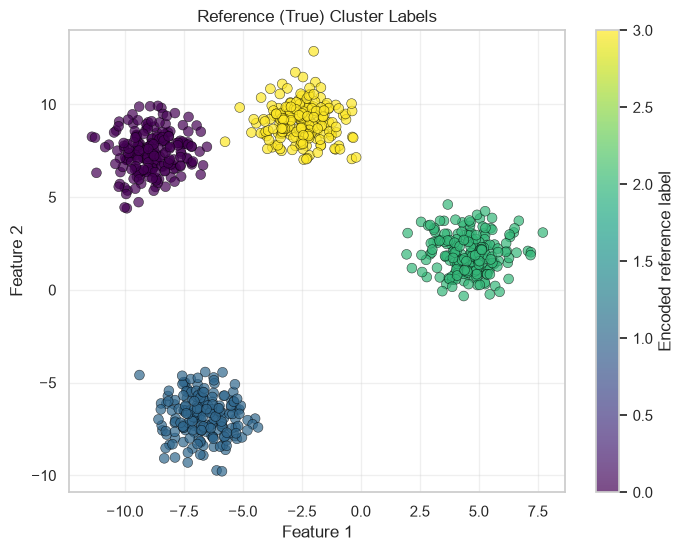

In [7]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X[:, 0], X[:, 1],
    c=pd.factorize(y_true)[0],
    cmap="viridis",
    alpha=0.7,
    edgecolors="black",
    linewidth=0.4,
    s=50
)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Reference (True) Cluster Labels")
plt.colorbar(scatter, label="Encoded reference label")
plt.grid(alpha=0.3)
plt.show()

### 6. Standardize the features

K-means relies on Euclidean distance. A feature with a larger numerical scale can dominate the distance calculation, even when it is not intrinsically more important.

Standardization applies

$$z = \\frac{x-\\mu}{\\sigma}$$

to each feature, where $\\mu$ and $\\sigma$ are estimated from the dataset. The scaler is fitted once on the training observations and must also be used for every later prediction.

**Note:** Standardization is a modeling decision. It is appropriate when comparable feature scales are desired, but it changes the geometry of the data.

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scaled_summary = pd.DataFrame(
    X_scaled, columns=["Feature_1_scaled", "Feature_2_scaled"]
).describe()

display(scaled_summary)

print("Scaled feature means:", X_scaled.mean(axis=0))
print("Scaled feature standard deviations:", X_scaled.std(axis=0))

,Feature_1_scaled,Feature_2_scaled
count,8.000000e+02,8.000000e+02
mean,-3.663736e-17,2.220446e-17
std,1.000626e+00,1.000626e+00
min,-1.542298e+00,-2.020216e+00
25%,-8.217238e-01,-6.771621e-01
50%,-2.396518e-01,2.443153e-01
75%,7.100238e-01,8.552558e-01
max,2.126625e+00,1.590032e+00


Scaled feature means: [-3.66373598e-17  2.22044605e-17]
Scaled feature standard deviations: [1. 1.]


## Selecting the number of clusters

### 7. Compare candidate values of K

K-means requires the number of clusters, $K$, to be specified.

We examine candidate values from 2 to 9 using two complementary measures:

- **Inertia:** the sum of squared distances from each observation to its assigned centroid. Lower values indicate more compact clusters. Inertia generally decreases as K increases.
- **Silhouette score:** compares within-cluster cohesion with separation from the nearest alternative cluster. It ranges from −1 to +1; larger values generally indicate better separation.

Neither measure identifies the correct K automatically in every dataset.

In [9]:
K_range = range(2, min(10, n_samples))
inertias = []
silhouette_scores = []

for k in K_range:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10,
        max_iter=300
    )
    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

selection_results = pd.DataFrame({
    "K": list(K_range),
    "Inertia": inertias,
    "Silhouette_Score": silhouette_scores
})

display(selection_results)

,K,Inertia,Silhouette_Score
0,2,853.000216,0.552680
1,3,202.036117,0.736584
2,4,48.253755,0.796778
3,5,43.523256,0.684657
4,6,39.149311,0.562964
5,7,34.705484,0.429238
6,8,30.620345,0.330536
7,9,28.054619,0.338262


### 8. Plot the elbow and silhouette curves

**Elbow method:** Look for a value of K after which additional clusters produce only modest reductions in inertia. The elbow can be subjective.

**Silhouette analysis:** Compare the average silhouette scores across candidate K values. A higher score is evidence of better separation under the chosen distance representation, but it does not prove that the corresponding partition is semantically correct.

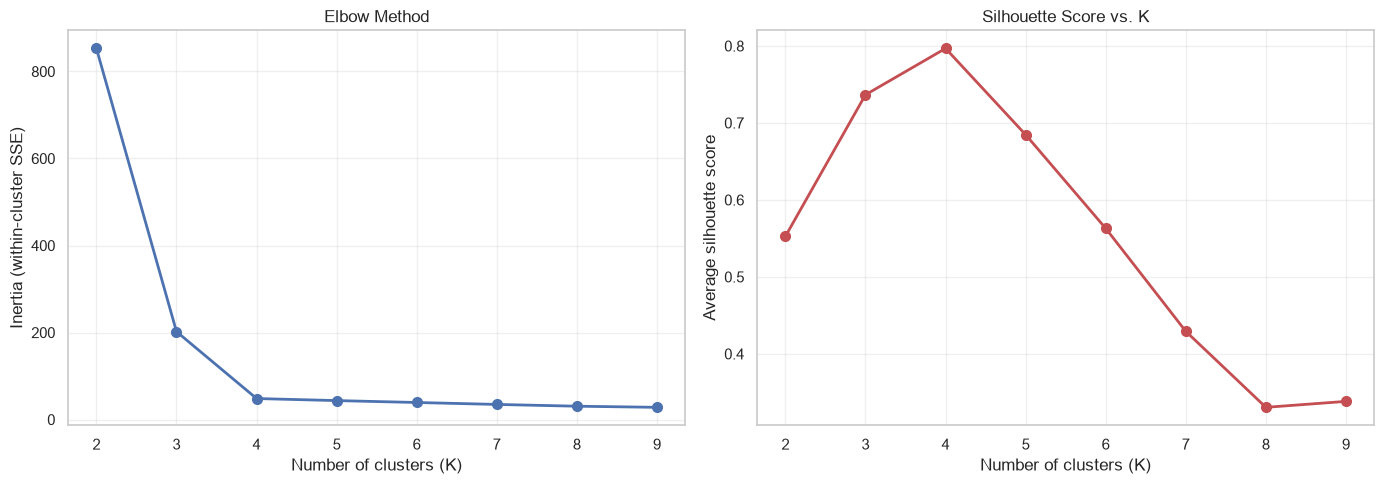

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(K_range), inertias, "bo-", linewidth=2, markersize=7)
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[0].set_title("Elbow Method")
axes[0].grid(alpha=0.3)

axes[1].plot(list(K_range), silhouette_scores, "ro-", linewidth=2, markersize=7)
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Average silhouette score")
axes[1].set_title("Silhouette Score vs. K")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 9. Select K and fit the final K-means model

The original experiment uses `K=4`. We retain that as the default for reproducibility. Review the elbow and silhouette plots before changing it.

The reference labels are not used to choose K. This avoids using the answer labels to guide an ostensibly unsupervised model.

In [11]:
OPTIMAL_K = 4  # Review the model-selection plots before changing this value.

if OPTIMAL_K >= n_samples:
    raise ValueError("K must be smaller than the number of observations.")

kmeans = KMeans(
    n_clusters=OPTIMAL_K,
    random_state=RANDOM_STATE,
    n_init=10,
    max_iter=300
)

predicted_clusters = kmeans.fit_predict(X_scaled)

print("Requested K:", OPTIMAL_K)
print("Realized clusters:", np.unique(predicted_clusters))
print("Iterations used:", kmeans.n_iter_)
print("Final inertia:", kmeans.inertia_)

Requested K: 4
Realized clusters: [0 1 2 3]
Iterations used: 2
Final inertia: 48.253754895472355


### 10. Calculate silhouette values for individual observations

The silhouette coefficient of observation $i$ is

$$s(i)=\\frac{b(i)-a(i)}{\\max(a(i),b(i))},$$

where $a(i)$ is its average distance to observations in its own cluster, and $b(i)$ is the smallest average distance to observations in another cluster.

- Values near +1 suggest that the observation is well matched to its assigned cluster.
- Values near 0 suggest that it lies close to a cluster boundary.
- Negative values suggest that another cluster may be a better fit.

The overall silhouette score is the mean of the individual scores.

In [12]:
silhouette_vals = silhouette_samples(X_scaled, predicted_clusters)
final_silhouette = silhouette_score(X_scaled, predicted_clusters)

print(f"Overall silhouette score: {final_silhouette:.4f}")
print(f"Mean individual score:    {silhouette_vals.mean():.4f}")
print(f"Median:                   {np.median(silhouette_vals):.4f}")
print(f"Standard deviation:       {silhouette_vals.std():.4f}")
print(f"Minimum:                  {silhouette_vals.min():.4f}")
print(f"Maximum:                  {silhouette_vals.max():.4f}")

Overall silhouette score: 0.7968
Mean individual score:    0.7968
Median:                   0.8120
Standard deviation:       0.0844
Minimum:                  0.0641
Maximum:                  0.9061


### 11. Create a comprehensive results table

The table combines original feature values, supplied reference labels, predicted cluster IDs, individual silhouette scores, and distance to the assigned centroid.

**Distance interpretation:** A large distance means that an observation is relatively far from its assigned centroid in standardized feature space. It is not a probability and should not be interpreted as a confidence score.

In [13]:
distances_to_centroids = kmeans.transform(X_scaled)
nearest_centroid_distance = distances_to_centroids.min(axis=1)

results_df = pd.DataFrame({
    "Data_Point_ID": np.arange(1, n_samples + 1),
    "Feature_1": X[:, 0],
    "Feature_2": X[:, 1],
    "True_Cluster": y_true,
    "Predicted_Cluster": predicted_clusters,
    "Silhouette_Score": silhouette_vals,
    "Distance_to_Centroid": nearest_centroid_distance
})

display(results_df.head(20))

,Data_Point_ID,Feature_1,Feature_2,True_Cluster,Predicted_Cluster,Silhouette_Score,Distance_to_Centroid
0,1,-9.226505,7.493939,3,3,0.821079,0.081176
1,2,-6.329575,-7.848454,2,0,0.889310,0.178768
2,3,3.849404,2.444638,1,2,0.833979,0.162941
3,4,3.935535,0.564708,1,2,0.824799,0.254389
4,5,5.199669,3.053950,1,2,0.830025,0.211071
5,6,-8.272818,5.562760,3,3,0.702880,0.309614
6,7,-2.285105,9.026879,0,1,0.834145,0.041724
7,8,-2.232507,9.841469,0,1,0.816285,0.135903
8,9,-6.266109,-7.902902,2,0,0.886894,0.191579
9,10,-9.484292,6.524331,3,3,0.800242,0.189290


## Comparing predicted clusters with reference labels

### 12. Why cluster labels must be matched

Cluster IDs are arbitrary. For example, K-means may identify the same partition as the reference labels but use predicted IDs `2, 0, 1` where the reference uses `0, 1, 2`.

A direct comparison would incorrectly count these as mismatches. We therefore use the **Hungarian algorithm** to find the one-to-one mapping between predicted cluster IDs and reference labels that maximizes the number of matches.

This comparison is an external evaluation step. It does not change the fitted K-means model.

In [14]:
true_labels, true_encoded = np.unique(y_true, return_inverse=True)
pred_labels, pred_encoded = np.unique(predicted_clusters, return_inverse=True)

cm_before = confusion_matrix(true_encoded, pred_encoded)

print("Confusion matrix before label mapping:")
display(pd.DataFrame(
    cm_before,
    index=[f"True {label}" for label in true_labels],
    columns=[f"Predicted {label}" for label in pred_labels]
))

# Find the one-to-one mapping that maximizes matched observations.
row_ind, col_ind = linear_sum_assignment(-cm_before)

# Map predicted cluster ID -> reference label.
label_mapping = {
    pred_labels[col]: true_labels[row]
    for row, col in zip(row_ind, col_ind)
}

print("Optimal mapping (predicted cluster -> reference label):")
print(label_mapping)

results_df["Predicted_Cluster_Remapped"] = (
    results_df["Predicted_Cluster"].map(label_mapping)
)

results_df["Cluster_Match"] = (
    results_df["True_Cluster"] == results_df["Predicted_Cluster_Remapped"]
)

matched_count = int(results_df["Cluster_Match"].sum())
accuracy = 100 * matched_count / n_samples

print(f"\nMatched observations: {matched_count} / {n_samples}")
print(f"Label-matched accuracy: {accuracy:.2f}%")

Confusion matrix before label mapping:


,Predicted 0,Predicted 1,Predicted 2,Predicted 3
True 0,0,199,0,1
True 1,0,0,200,0
True 2,200,0,0,0
True 3,0,0,0,200


Optimal mapping (predicted cluster -> reference label):
{np.int32(1): np.int64(0), np.int32(2): np.int64(1), np.int32(0): np.int64(2), np.int32(3): np.int64(3)}

Matched observations: 799 / 800
Label-matched accuracy: 99.88%


### 13. Inspect the confusion matrix after label mapping

After mapping, the diagonal entries represent observations whose predicted cluster corresponds to the reference label.

**Caution:** This accuracy-like measure depends on a one-to-one mapping. It is most straightforward when the number of predicted clusters equals the number of reference classes. If K differs from the number of reference classes, some labels cannot be matched one-to-one. For a more label-invariant evaluation, also report the Adjusted Rand Index (ARI) or Normalized Mutual Information (NMI).

In [15]:
cm_after = confusion_matrix(
    y_true,
    results_df["Predicted_Cluster_Remapped"],
    labels=true_labels
)

cm_after_df = pd.DataFrame(
    cm_after,
    index=[f"True {label}" for label in true_labels],
    columns=[f"Mapped prediction {label}" for label in true_labels]
)

display(cm_after_df)

ari = adjusted_rand_score(y_true, predicted_clusters)
nmi = normalized_mutual_info_score(y_true, predicted_clusters)

print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")

,Mapped prediction 0,Mapped prediction 1,Mapped prediction 2,Mapped prediction 3
True 0,199,0,0,1
True 1,0,200,0,0
True 2,0,0,200,0
True 3,0,0,0,200


Adjusted Rand Index (ARI): 0.9967
Normalized Mutual Information (NMI): 0.9943


### 14. Summarize centroids in original feature units

K-means was fitted using standardized values. Its `cluster_centers_` are therefore in standardized coordinates.

For interpretation and plotting alongside the original data, use `scaler.inverse_transform()` to convert the centroids back to the original feature scale.

In [16]:
centers_scaled = kmeans.cluster_centers_
centers_original = scaler.inverse_transform(centers_scaled)

centroid_df = pd.DataFrame(
    centers_original,
    columns=["Centroid_Feature_1", "Centroid_Feature_2"]
)
centroid_df.index.name = "Predicted_Cluster"

display(centroid_df)

results_df = results_df.merge(
    centroid_df,
    left_on="Predicted_Cluster",
    right_index=True,
    how="left"
)

print(f"Final silhouette score: {final_silhouette:.4f}")
print(f"Total observations: {len(results_df)}")
print("Result columns:", list(results_df.columns))
display(results_df.head(20))

,Centroid_Feature_1,Centroid_Feature_2
Predicted_Cluster,,
0,-6.681686,-6.810474
1,-2.501357,9.052956
2,4.592315,1.950451
3,-8.812083,7.392876


Final silhouette score: 0.7968
Total observations: 800
Result columns: ['Data_Point_ID', 'Feature_1', 'Feature_2', 'True_Cluster', 'Predicted_Cluster', 'Silhouette_Score', 'Distance_to_Centroid', 'Predicted_Cluster_Remapped', 'Cluster_Match', 'Centroid_Feature_1', 'Centroid_Feature_2']


,Data_Point_ID,Feature_1,Feature_2,True_Cluster,Predicted_Cluster,Silhouette_Score,Distance_to_Centroid,Predicted_Cluster_Remapped,Cluster_Match,Centroid_Feature_1,Centroid_Feature_2
0,1,-9.226505,7.493939,3,3,0.821079,0.081176,3,True,-8.812083,7.392876
1,2,-6.329575,-7.848454,2,0,0.889310,0.178768,2,True,-6.681686,-6.810474
2,3,3.849404,2.444638,1,2,0.833979,0.162941,1,True,4.592315,1.950451
3,4,3.935535,0.564708,1,2,0.824799,0.254389,1,True,4.592315,1.950451
4,5,5.199669,3.053950,1,2,0.830025,0.211071,1,True,4.592315,1.950451
5,6,-8.272818,5.562760,3,3,0.702880,0.309614,3,True,-8.812083,7.392876
6,7,-2.285105,9.026879,0,1,0.834145,0.041724,0,True,-2.501357,9.052956
7,8,-2.232507,9.841469,0,1,0.816285,0.135903,0,True,-2.501357,9.052956
8,9,-6.266109,-7.902902,2,0,0.886894,0.191579,2,True,-6.681686,-6.810474
9,10,-9.484292,6.524331,3,3,0.800242,0.189290,3,True,-8.812083,7.392876


### 15. Visualize the predicted clusters and centroids

Each point is colored by its predicted cluster. Red `X` markers represent the cluster centroids.

The centroids are plotted in original feature units, so their coordinates are directly comparable with the raw observations.

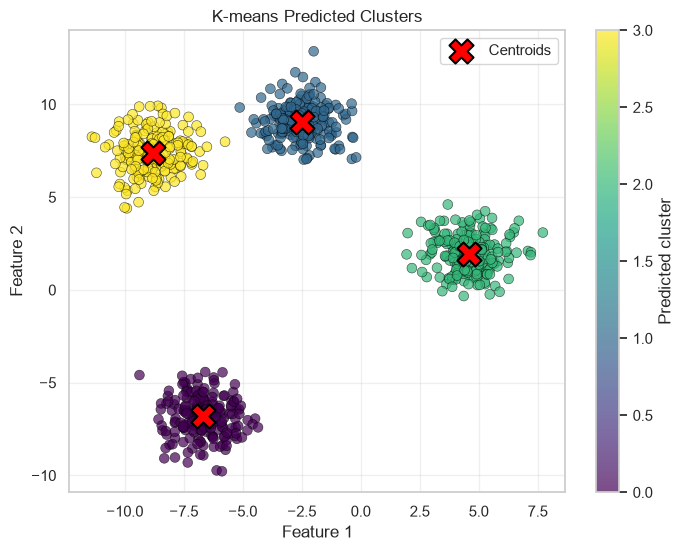

In [17]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    results_df["Feature_1"],
    results_df["Feature_2"],
    c=results_df["Predicted_Cluster"],
    cmap="viridis",
    alpha=0.7,
    edgecolors="black",
    linewidth=0.4,
    s=50
)

plt.scatter(
    centers_original[:, 0],
    centers_original[:, 1],
    c="red",
    marker="X",
    s=300,
    edgecolors="black",
    linewidth=1.5,
    label="Centroids"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-means Predicted Clusters")
plt.colorbar(scatter, label="Predicted cluster")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 16. Visualize silhouette scores by observation

This plot colors each observation according to its silhouette coefficient. Green values indicate stronger assignments; values near zero indicate observations near cluster boundaries; negative values indicate potentially questionable assignments.

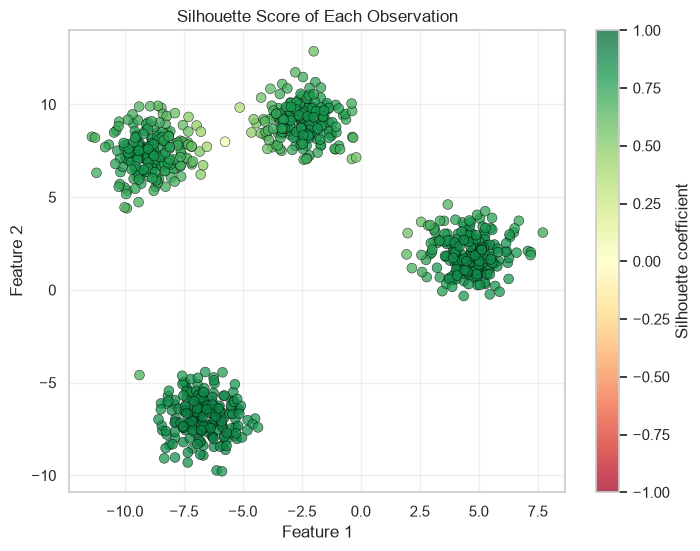

In [18]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    results_df["Feature_1"],
    results_df["Feature_2"],
    c=results_df["Silhouette_Score"],
    cmap="RdYlGn",
    vmin=-1,
    vmax=1,
    alpha=0.75,
    edgecolors="black",
    linewidth=0.4,
    s=50
)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Silhouette Score of Each Observation")
plt.colorbar(scatter, label="Silhouette coefficient")
plt.grid(alpha=0.3)
plt.show()

### 17. Draw the silhouette plot for each cluster

Within each cluster, observations are sorted by their silhouette coefficient. The red dashed line marks the overall mean silhouette score.

A cluster with many negative or near-zero values may be poorly separated or may contain observations that fit another cluster better.

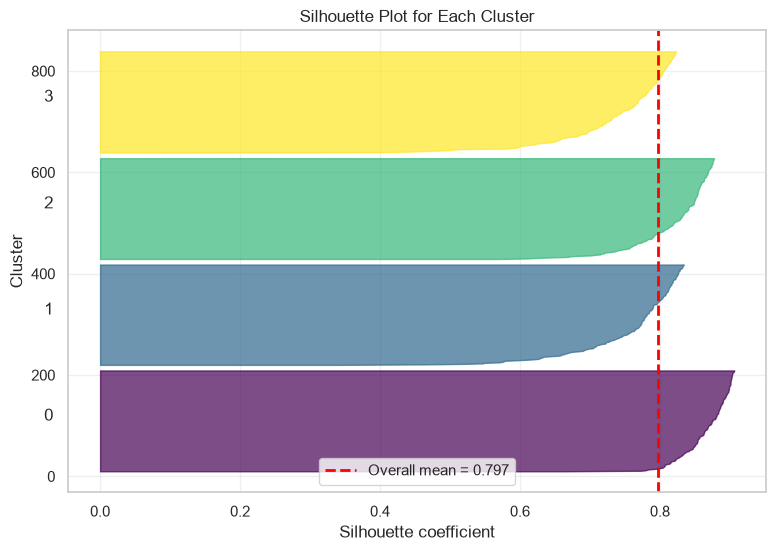

In [19]:
fig, ax = plt.subplots(figsize=(9, 6))

y_lower = 10
colors = plt.cm.viridis(np.linspace(0, 1, OPTIMAL_K))

for cluster_id in range(OPTIMAL_K):
    cluster_values = silhouette_vals[predicted_clusters == cluster_id]
    cluster_values.sort()

    size_cluster = len(cluster_values)
    y_upper = y_lower + size_cluster

    ax.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        cluster_values,
        facecolor=colors[cluster_id],
        edgecolor=colors[cluster_id],
        alpha=0.7
    )
    ax.text(-0.08, y_lower + 0.5 * size_cluster, str(cluster_id))
    y_lower = y_upper + 10

ax.axvline(
    final_silhouette,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Overall mean = {final_silhouette:.3f}"
)
ax.set_xlabel("Silhouette coefficient")
ax.set_ylabel("Cluster")
ax.set_title("Silhouette Plot for Each Cluster")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### 18. Examine the distribution of silhouette scores

The histograms show how silhouette values are distributed within each predicted cluster. They complement the silhouette plot by making the spread and concentration of scores easier to compare.

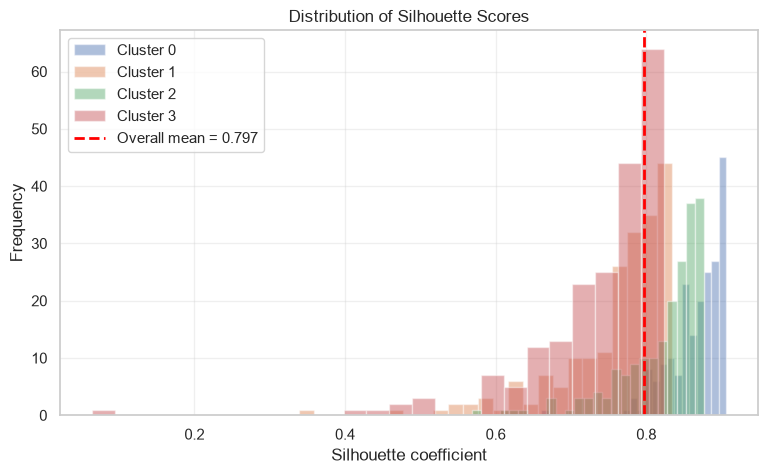

In [20]:
plt.figure(figsize=(9, 5))

for cluster_id in range(OPTIMAL_K):
    cluster_values = silhouette_vals[predicted_clusters == cluster_id]
    plt.hist(
        cluster_values,
        bins=25,
        alpha=0.45,
        label=f"Cluster {cluster_id}"
    )

plt.axvline(
    final_silhouette,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Overall mean = {final_silhouette:.3f}"
)
plt.xlabel("Silhouette coefficient")
plt.ylabel("Frequency")
plt.title("Distribution of Silhouette Scores")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 19. Compare cluster sizes

Cluster size indicates how many observations K-means assigned to each group. Very small clusters may deserve further inspection, but size imbalance is not automatically evidence of a poor solution.

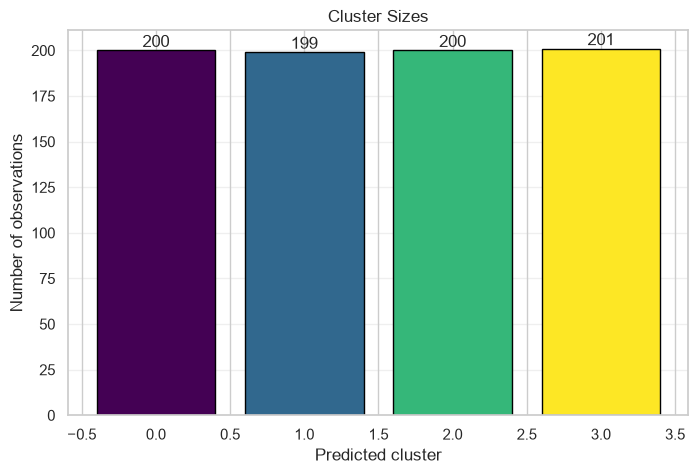

,Number_of_Observations
Predicted_Cluster,
0,200
1,199
2,200
3,201


In [21]:
cluster_sizes = (
    results_df["Predicted_Cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))
bars = plt.bar(
    cluster_sizes.index,
    cluster_sizes.values,
    color=colors,
    edgecolor="black",
    linewidth=1
)

plt.xlabel("Predicted cluster")
plt.ylabel("Number of observations")
plt.title("Cluster Sizes")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom"
    )

plt.grid(axis="y", alpha=0.3)
plt.show()

display(cluster_sizes.rename("Number_of_Observations").to_frame())

### 20. Compare average silhouette scores across clusters

The overall average is shown by the red dashed line. The horizontal reference lines at 0.5 and 0.7 are illustrative guides only. They are not universal quality thresholds; interpretation depends on the dataset, application, and cluster structure.

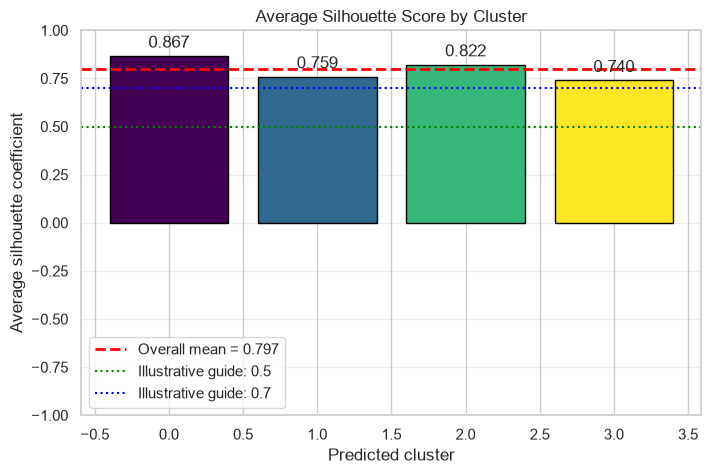

In [22]:
cluster_avg_silhouette = (
    results_df.groupby("Predicted_Cluster")["Silhouette_Score"]
    .mean()
    .reindex(range(OPTIMAL_K))
)

plt.figure(figsize=(8, 5))
bars = plt.bar(
    cluster_avg_silhouette.index,
    cluster_avg_silhouette.values,
    color=colors,
    edgecolor="black",
    linewidth=1
)

plt.axhline(
    final_silhouette,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Overall mean = {final_silhouette:.3f}"
)
plt.axhline(0.5, color="green", linestyle=":", label="Illustrative guide: 0.5")
plt.axhline(0.7, color="blue", linestyle=":", label="Illustrative guide: 0.7")

plt.xlabel("Predicted cluster")
plt.ylabel("Average silhouette coefficient")
plt.title("Average Silhouette Score by Cluster")
plt.ylim(-1, 1)
plt.legend()

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.025,
        f"{height:.3f}",
        ha="center",
        va="bottom"
    )

plt.grid(axis="y", alpha=0.3)
plt.show()

## Predicting new observations

### 21. Generate new points and assign clusters

After fitting, K-means can assign a new observation to its nearest learned centroid.

This example creates two groups of synthetic points:

1. **Random points:** sampled in the original feature scale as a simple demonstration.
2. **Points near learned centroids:** generated in standardized space, then transformed back to the original feature scale.

The second procedure is important: `kmeans.cluster_centers_` are in standardized coordinates because the model was fitted on `X_scaled`. We must not treat those coordinates as raw feature values.

In [23]:
np.random.seed(123)

n_random_points = 5
n_near_centroid_points = 5

# Method 1: random points in original feature units
feature_std = X.std(axis=0, ddof=0)
feature_std = np.where(feature_std == 0, 1.0, feature_std)

new_X_random = (
    np.random.randn(n_random_points, n_features) * feature_std
    + X.mean(axis=0)
)

# Method 2: generate points near learned centroids in standardized space
new_X_near_centers_scaled = []

for i in range(n_near_centroid_points):
    center_scaled = centers_scaled[i % OPTIMAL_K]
    noise = np.random.randn(n_features) * 0.5
    new_X_near_centers_scaled.append(center_scaled + noise)

new_X_near_centers_scaled = np.array(new_X_near_centers_scaled)
new_X_near_centers = scaler.inverse_transform(new_X_near_centers_scaled)

# Combine both sets in original feature units
new_X = np.vstack([new_X_random, new_X_near_centers])

print(f"Generated {len(new_X)} new observations.")
display(pd.DataFrame(new_X, columns=["Feature_1", "Feature_2"]))

Generated 10 new observations.


,Feature_1,Feature_2
0,-9.013520,9.149702
1,-1.884588,-6.553065
2,-6.372456,13.252145
3,-15.998894,0.204248
4,3.235530,-2.541796
5,-8.449807,-7.107480
6,1.382884,7.049367
7,3.435989,0.588331
8,-3.066861,14.250609
9,-4.066684,-5.599398


### 22. Predict cluster IDs for the new observations

Transform the new observations with the **same fitted scaler**. Then use the fitted K-means model to predict their cluster IDs.

The distance to the nearest centroid is a geometric distance, not a calibrated confidence probability. The example's distance bands are only a rough teaching heuristic.

In [24]:
new_X_scaled = scaler.transform(new_X)

new_predictions = kmeans.predict(new_X_scaled)
new_distances = kmeans.transform(new_X_scaled)
nearest_distances = new_distances.min(axis=1)

new_results = pd.DataFrame({
    "Feature_1": new_X[:, 0],
    "Feature_2": new_X[:, 1],
    "Predicted_Cluster": new_predictions,
    "Distance_to_Centroid": nearest_distances
})

def distance_band(distance):
    if distance < 1.0:
        return "Near centroid"
    elif distance < 2.0:
        return "Moderate distance"
    return "Far from centroid"

new_results["Distance_Interpretation"] = new_results[
    "Distance_to_Centroid"
].apply(distance_band)

display(new_results)

for i, row in new_results.iterrows():
    print(
        f"Point {i + 1}: "
        f"[{row['Feature_1']:.2f}, {row['Feature_2']:.2f}] "
        f"-> Cluster {row['Predicted_Cluster']} "
        f"(distance = {row['Distance_to_Centroid']:.2f}; "
        f"{row['Distance_Interpretation']})"
    )

,Feature_1,Feature_2,Predicted_Cluster,Distance_to_Centroid,Distance_Interpretation
0,-9.013520,9.149702,3,0.282764,Near centroid
1,-1.884588,-6.553065,0,0.921859,Near centroid
2,-6.372456,13.252145,1,1.000278,Moderate distance
3,-15.998894,0.204248,3,1.793681,Moderate distance
4,3.235530,-2.541796,2,0.762134,Near centroid
5,-8.449807,-7.107480,0,0.342730,Near centroid
6,1.382884,7.049367,1,0.811240,Near centroid
7,3.435989,0.588331,2,0.310556,Near centroid
8,-3.066861,14.250609,1,0.835792,Near centroid
9,-4.066684,-5.599398,0,0.537881,Near centroid


Point 1: [-9.01, 9.15] -> Cluster 3 (distance = 0.28; Near centroid)
Point 2: [-1.88, -6.55] -> Cluster 0 (distance = 0.92; Near centroid)
Point 3: [-6.37, 13.25] -> Cluster 1 (distance = 1.00; Moderate distance)
Point 4: [-16.00, 0.20] -> Cluster 3 (distance = 1.79; Moderate distance)
Point 5: [3.24, -2.54] -> Cluster 2 (distance = 0.76; Near centroid)
Point 6: [-8.45, -7.11] -> Cluster 0 (distance = 0.34; Near centroid)
Point 7: [1.38, 7.05] -> Cluster 1 (distance = 0.81; Near centroid)
Point 8: [3.44, 0.59] -> Cluster 2 (distance = 0.31; Near centroid)
Point 9: [-3.07, 14.25] -> Cluster 1 (distance = 0.84; Near centroid)
Point 10: [-4.07, -5.60] -> Cluster 0 (distance = 0.54; Near centroid)


### 23. Visualize predictions for new observations

- Circles represent the original observations.
- Red `X` markers represent learned centroids.
- Stars represent the new observations.
- The star color indicates the cluster predicted by the fitted model.

The new points are assigned using the existing model. They do not update or retrain the centroids.

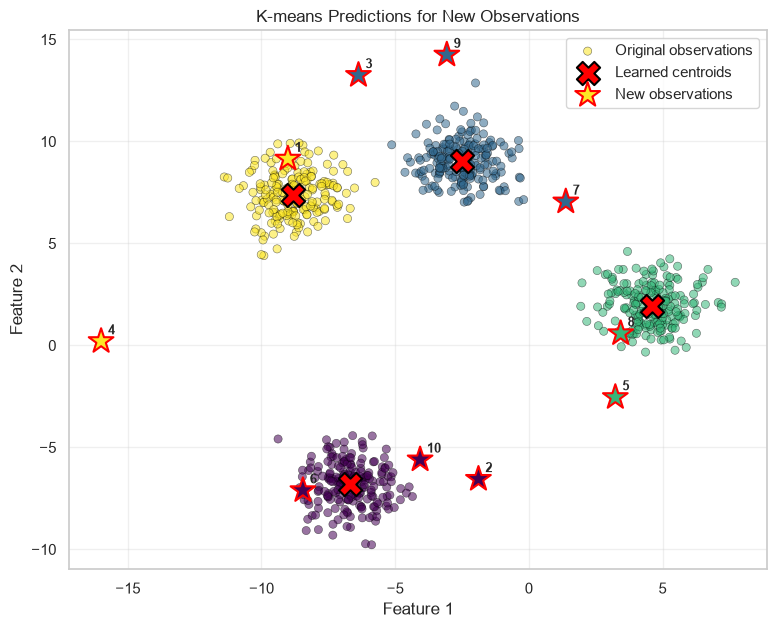

In [25]:
plt.figure(figsize=(9, 7))

plt.scatter(
    X[:, 0], X[:, 1],
    c=predicted_clusters,
    cmap="viridis",
    alpha=0.55,
    edgecolors="black",
    linewidth=0.4,
    s=35,
    label="Original observations"
)

plt.scatter(
    centers_original[:, 0],
    centers_original[:, 1],
    c="red",
    marker="X",
    s=280,
    edgecolors="black",
    linewidth=1.5,
    label="Learned centroids",
    zorder=5
)

plt.scatter(
    new_X[:, 0],
    new_X[:, 1],
    c=new_predictions,
    cmap="viridis",
    marker="*",
    s=350,
    edgecolors="red",
    linewidth=1.5,
    label="New observations",
    zorder=6
)

for i, (x_point, y_point) in enumerate(new_X):
    plt.annotate(
        str(i + 1),
        xy=(x_point, y_point),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold"
    )

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-means Predictions for New Observations")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 24. Save the results

Save the observation-level results, new-point predictions, and figures for later inspection. Files are written to the notebook's current working directory.

In [26]:
results_df.to_csv("kmeans_clustering_results.csv", index=False)
new_results.to_csv("kmeans_new_point_predictions.csv", index=False)

print("Saved:")
print("- kmeans_clustering_results.csv")
print("- kmeans_new_point_predictions.csv")

Saved:
- kmeans_clustering_results.csv
- kmeans_new_point_predictions.csv
